# Fix rotated SiPMs
A quabo running the wrong firmware reads two of its four 8×8 SiPMs out rotated by 180°, so part of each shower
image lands in the wrong pixels: images break up at those SiPMs' edges and their Hillas parameters are wrong (e.g.
Winter's quabo 2 in September 2026). This notebook draws one telescope's quabos and SiPMs, so you can name the
rotated ones you've seen in its images, previews rotating them back, and reprocesses the affected nights with them
rotated back in the raw frames, before the pedestals, gain maps and cleaning.

**How to use it**
1. Pick the telescope (`TELESCOPE`) and the nights to fix (`DATES`) in **Selection**.
2. Use **Camera layout** to name the rotated SiPMs, `[row, col]`, and add an entry for them to
   `configs/analysis/rotated_sipm.yaml` (`first` and `last` night, `sipm`).
3. Run the notebook. **Before and after** previews the fix on the nights not reprocessed yet: check that the images
   come together.
4. Set `REPROCESS = True` and run **Reprocess**: it reprocesses `TELESCOPE` on each night in `DATES` whose output doesn't
   match the file (`heap.events.process_night()` rotates the listed SiPMs back). To undo a fix made by mistake, take
   the night out of the file and do the same. Any later processing of those nights (e.g.
   `process_pff.ipynb`) does the same, and output processed without the fix is no longer reused (it raises instead).
   **Before and after** always compares the data as read out with the data with the listed SiPMs rotated back, also
   after changing the list and reprocessing again.

Everything here is in the camera's own orientation, as the pixels are read out: images are not rotated after the
meridian flip, and centroids have no pointing corrections.

# Imports

In [1]:
import json

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle

from heap import events as ev
from heap.config import load_analysis_config, local_analysis
from heap.parameterize import CAMERA_CMAP, CAMERA_EXTENT, CAMERA_HALF_WIDTH, PLATE_SCALE, calc_params
from heap.rotated_sipm import ROTATED_SIPM_FILE, load_rotated_sipm, plot_layout, rotate_sipm, rotated_sipm_for

# Selection

In [2]:
CONFIG = local_analysis() # the analysis config configs/local.yaml names, or any other, e.g. Path("../configs/analysis/<name>.yaml")
cfg = load_analysis_config(CONFIG)

RAW_DATA_DIR = cfg["paths"]["raw_data_dir"]
OUTPUT_DIR = cfg["paths"]["output_dir"]

TELESCOPE = "Winter" # one of the config's telescopes
DATES = ["20260917", "20260918", "20260922"] # nights to fix; None = every night in OUTPUT_DIR with TELESCOPE's output

# before and after plots
MIN_PIXELS = 5 # images with fewer pixels are left out of the plots
N_IMAGES = 6 # images shown: the brightest in the rotated SiPMs
MIN_FRACTION = 0.5 # of their size in the rotated SiPMs' quabos, to leave out frames lit up all over the camera

# reprocessing, with the config's pipeline settings
REPROCESS = False # True = reprocess TELESCOPE on the nights in DATES that rotated_sipm.yaml lists SiPMs for, unless already done (slow)

In [3]:
MODULE = next(module for module, info in cfg["telescopes"].items() if info["name"] == TELESCOPE)
if DATES is None:
    DATES = sorted({path.parts[-4] for path in OUTPUT_DIR.glob(f"*/{TELESCOPE}/*/calibrations.npz")})
print(f"{TELESCOPE} ({MODULE}), {len(DATES)} nights: {DATES}")

Winter (module_253), 3 nights: ['20260917', '20260918', '20260922']


# Functions

In [4]:
SIPM_WIDTH = 8 * PLATE_SCALE # deg

def load_night(date):
    # TELESCOPE's cleaned images and Hillas parameters on night date, every source pooled
    images, params = [], []
    for npz in sorted((OUTPUT_DIR / date / TELESCOPE).glob("*/*.npz")):
        if npz.name == "calibrations.npz":
            continue
        with np.load(npz) as f:
            images.append(f["cleaned_images"])
            params.append(pd.DataFrame({k: f[k] for k in f.files if k != "cleaned_images"}).assign(Source=npz.parent.name))
    return np.concatenate(images), pd.concat(params, ignore_index=True)

def has_output(date):
    return any((OUTPUT_DIR / date / TELESCOPE).glob("*/calibrations.npz"))

def borrowers(dates):
    # TELESCOPE's nights in OUTPUT_DIR whose gain map is borrowed from one of dates (see heap.process_dataset.resolve_gain_map())
    nights = set()
    for path in OUTPUT_DIR.glob(f"*/{TELESCOPE}/*/calibrations.npz"):
        with np.load(path) as calib:
            gain_source = str(calib["gain_source"])
        if gain_source.startswith("other_night:") and gain_source.removeprefix("other_night:") in dates:
            nights.add(path.parts[-4])
    return sorted(nights)

def processed_with(date):
    # the sipms TELESCOPE's output on night date was processed with rotated back, from its processing.json
    path = OUTPUT_DIR / date / TELESCOPE / "processing.json"
    return json.loads(path.read_text()).get("rotated_sipm", []) if path.exists() else []

def preview(images, params, sipms):
    # images with sipms rotated by 180 deg and their Hillas parameters recomputed, without redoing the cleaning
    rotated = rotate_sipm(images, sipms)
    new = pd.DataFrame([calc_params(image) for image in rotated])
    return rotated, new.assign(Event=params.Event.to_numpy(), Timestamp=params.Timestamp.to_numpy(), Source=params.Source.to_numpy())

def quabo_sipms(sipms):
    # every SiPM of the quabos holding sipms
    quabos = {(row // 2, col // 2) for row, col in sipms}
    return [[2*qrow + i, 2*qcol + j] for qrow, qcol in sorted(quabos) for i in range(2) for j in range(2)]

def region_fraction(images, sipms):
    # the fraction of each image's size in sipms ([[row, col], ...])
    mask = np.zeros((32, 32), dtype=bool)
    for row, col in sipms:
        mask[8*row:8*row + 8, 8*col:8*col + 8] = True
    x = np.nan_to_num(images)
    with np.errstate(invalid="ignore", divide="ignore"):
        return x[:, mask].sum(axis=1) / x.sum(axis=(1, 2))

def draw_grid(ax, sipms=(), color="w"):
    # the quabo (thick) and SiPM (thin) edges, sipms outlined in red, and the SiPM rows and columns on the axes
    half = CAMERA_HALF_WIDTH
    for k in range(1, 4):
        lw = 1.5 if k == 2 else 0.5
        ax.axvline(-half + k*SIPM_WIDTH, color=color, lw=lw, alpha=0.6)
        ax.axhline(-half + k*SIPM_WIDTH, color=color, lw=lw, alpha=0.6)
    for row, col in sipms:
        ax.add_patch(Rectangle((-half + col*SIPM_WIDTH, -half + row*SIPM_WIDTH), SIPM_WIDTH, SIPM_WIDTH, fill=False, edgecolor="r", lw=1.5))
    centers = -half + (np.arange(4) + 0.5) * SIPM_WIDTH
    ax.set_xticks(centers, ["0", "1", "2", "3"])
    ax.set_yticks(centers, ["0", "1", "2", "3"])
    ax.tick_params(length=0, labelsize=8)
    ax.set(xlim=[-half, half], ylim=[-half, half], xlabel="SiPM col", ylabel="SiPM row")

def plot_image(ax, image, params, title, sipms=()):
    # one cleaned image with the SiPM grid and its Hillas ellipse
    ax.imshow(np.nan_to_num(image), origin="lower", extent=CAMERA_EXTENT, cmap=CAMERA_CMAP, vmin=0)
    draw_grid(ax, sipms)
    if params.N_pix > 0:
        hillas = params.copy()
        hillas["Telescope"] = title
        ev.draw_hillas(ax, hillas, "w")
    ax.set(xlim=[-CAMERA_HALF_WIDTH, CAMERA_HALF_WIDTH], ylim=[-CAMERA_HALF_WIDTH, CAMERA_HALF_WIDTH]) # the ellipse's axis line runs past them
    ax.set_title(title, fontsize=8)

def plot_centroids(ax, params, title, sipms=(), bins=np.linspace(-CAMERA_HALF_WIDTH, CAMERA_HALF_WIDTH, 33), **kwargs):
    # where images with MIN_PIXELS or more pixels are centered, in pixel bins
    params = params[params.N_pix >= MIN_PIXELS]
    counts = np.histogram2d(params.x_c, params.y_c, [bins, bins])[0].T # [y, x], like the images
    im = ax.imshow(counts, origin="lower", extent=CAMERA_EXTENT, **({"cmap": "viridis", "vmin": 0} | kwargs))
    draw_grid(ax, sipms)
    ax.set_title(title, fontsize=9)
    return im, counts

# Camera layout
`TELESCOPE`'s quabos, labelled with their IP addresses (the module's address, `4 × module number`, plus the quabo number,
as in the run folders' `quabo_uids.json`), and their SiPMs, named `[row, col]` as in `rotated_sipm.yaml`.
They're drawn as every image below is plotted: X along the pixel columns and Y along the pixel rows; the plots below
label the SiPM rows and columns on their axes. The SiPMs `rotated_sipm.yaml` lists for `TELESCOPE` are filled in
red. Each quabo's place in the image comes from ph1024 frames missing that quabo's packet, where its 16×16 quadrant
reads 0 (`heap.rotated_sipm.QUABO_QUADRANTS`).

rotated_sipm.yaml: Winter SiPMs [[2, 3], [3, 2]] rotated back from 20260917 to 20260922


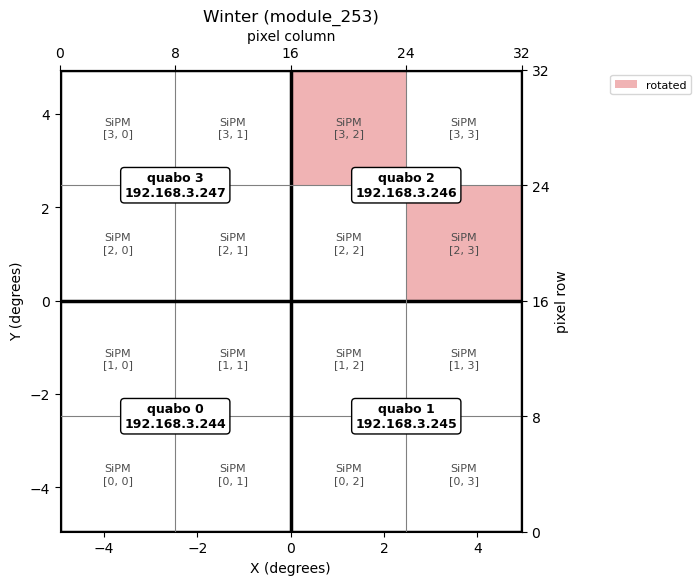

In [5]:
listed = load_rotated_sipm().get(TELESCOPE) or []
for entry in listed:
    print(f"{ROTATED_SIPM_FILE.name}: {TELESCOPE} SiPMs {entry['sipm']} rotated back from {entry['first']} to {entry['last']}")
if not listed:
    print(f"{ROTATED_SIPM_FILE.name} lists no SiPMs for {TELESCOPE}")
highlight = sorted({tuple(sipm) for entry in listed for sipm in entry["sipm"]})
fig, ax = plt.subplots(figsize=(7, 6))
plot_layout(ax, MODULE, [list(sipm) for sipm in highlight])
ax.set_title(f"{TELESCOPE} ({MODULE})")
plt.show()

# Reprocess
With `REPROCESS`, every night in `DATES` whose output doesn't match `rotated_sipm.yaml` (processed with other SiPMs
rotated back than it lists for `TELESCOPE` that night, if any) is reprocessed for `TELESCOPE` alone
(`heap.events.process_night()` with the config's pipeline settings, overwriting its output in `OUTPUT_DIR`). Then so is
every night of `TELESCOPE` that borrows its gain map from one of those, to borrow the new one. Each night's output as it
was is kept in `before` for **Before and after**. Rerun the analysis notebooks on these nights afterwards.

In [6]:
def reprocess(date):
    # reprocess TELESCOPE on night date, keeping its output as it was in before (the first time)
    if date not in before and has_output(date):
        before[date] = (*load_night(date), processed_with(date))
    ev.process_night(
        RAW_DATA_DIR / date, OUTPUT_DIR, date, {MODULE: cfg["telescopes"][MODULE]},
        data_product=cfg["pipeline"]["data_product"], image_threshold=cfg["pipeline"]["image_threshold"],
        border_threshold=cfg["pipeline"]["border_threshold"], keep_brightest_island=cfg["pipeline"]["keep_brightest_island"],
        reprocess=True,
    )

FIX_DATES = [date for date in DATES if rotated_sipm_for(TELESCOPE, date)]
for date in DATES:
    print(f"{date}: {ROTATED_SIPM_FILE.name} lists {rotated_sipm_for(TELESCOPE, date) or 'no'} SiPMs, output processed with "
          f"{processed_with(date) or 'no'} SiPMs rotated back")
TO_REPROCESS = [date for date in DATES if processed_with(date) != rotated_sipm_for(TELESCOPE, date)]
before = {}
if not TO_REPROCESS:
    print("every night's output matches the file")
elif not REPROCESS:
    print(f"Set REPROCESS = True to reprocess {TO_REPROCESS}.")
    if borrowers(TO_REPROCESS):
        print(f"{borrowers(TO_REPROCESS)} borrow a gain map from one of them, so they will be reprocessed again afterwards.")
else:
    for date in TO_REPROCESS:
        reprocess(date)
    again = borrowers(TO_REPROCESS)
    for date in again:
        reprocess(date)
    print(f"reprocessed {TO_REPROCESS}" + (f", then {again}, which borrow their gain maps" if again else ""))

20260917: rotated_sipm.yaml lists [[2, 3], [3, 2]] SiPMs, output processed with no SiPMs rotated back
20260918: rotated_sipm.yaml lists [[2, 3], [3, 2]] SiPMs, output processed with no SiPMs rotated back
20260922: rotated_sipm.yaml lists [[2, 3], [3, 2]] SiPMs, output processed with no SiPMs rotated back
Set REPROCESS = True to reprocess ['20260917', '20260918', '20260922'].
['20260917'] borrow a gain map from one of them, so they will be reprocessed again afterwards.


# Before and after
Each night in `FIX_DATES` (the nights in `DATES` that `rotated_sipm.yaml` lists SiPMs for): "before" is the data as
read out, and "after" is the data with the SiPMs `rotated_sipm.yaml` lists now rotated back, however the night was
processed in between (e.g. reprocessed with another list before). Each side is processed output when there's output
with exactly that layout (from disk, or kept by **Reprocess** above), and otherwise a preview: output with another
layout, with the SiPMs that differ rotated and the Hillas parameters recomputed (`heap.parameterize.calc_params()`),
without redoing the pedestals and cleaning. A preview's images are cleaned in another layout: the cleaning kept each
image's brightest island as connected there, so some previews cut a shower into pieces that reprocessing keeps whole,
and the other way round.

In [7]:
def changed(rotated, wanted):
    # the SiPMs to rotate to get from output with rotated rotated back to one with wanted rotated back: the ones in one list only
    return [list(sipm) for sipm in sorted({tuple(s) for s in rotated} ^ {tuple(s) for s in wanted})]

def with_layout(images, params, rotated, wanted):
    # output processed with rotated rotated back, as with wanted rotated back: itself if they're the same, else a preview
    if changed(rotated, wanted):
        return (*preview(images, params, changed(rotated, wanted)), "preview")
    return images, params, "processed"

comparison = {} # date: (before images, before params, after images, after params, before kind, after kind)
for date in FIX_DATES:
    sipms = rotated_sipm_for(TELESCOPE, date)
    images, params = load_night(date)
    # before: as read out, from the output kept before reprocessing if any (it may already have been fixed), else from disk
    old = before[date] if date in before else (images, params, processed_with(date))
    images_before, params_before, before_kind = with_layout(*old, [])
    images_after, params_after, after_kind = with_layout(images, params, processed_with(date), sipms)
    comparison[date] = (images_before, params_before, images_after, params_after, before_kind, after_kind)
    print(f"{date}: before (as read out) {before_kind}, after ({sipms} rotated back) {after_kind}, {len(params)} images")

20260917: before (as read out) processed, after ([[2, 3], [3, 2]] rotated back) preview, 13797 images
20260918: before (as read out) processed, after ([[2, 3], [3, 2]] rotated back) preview, 117961 images
20260922: before (as read out) processed, after ([[2, 3], [3, 2]] rotated back) preview, 23678 images


## Image centroids
Every night in `FIX_DATES` pooled, the rotated SiPMs outlined in red.

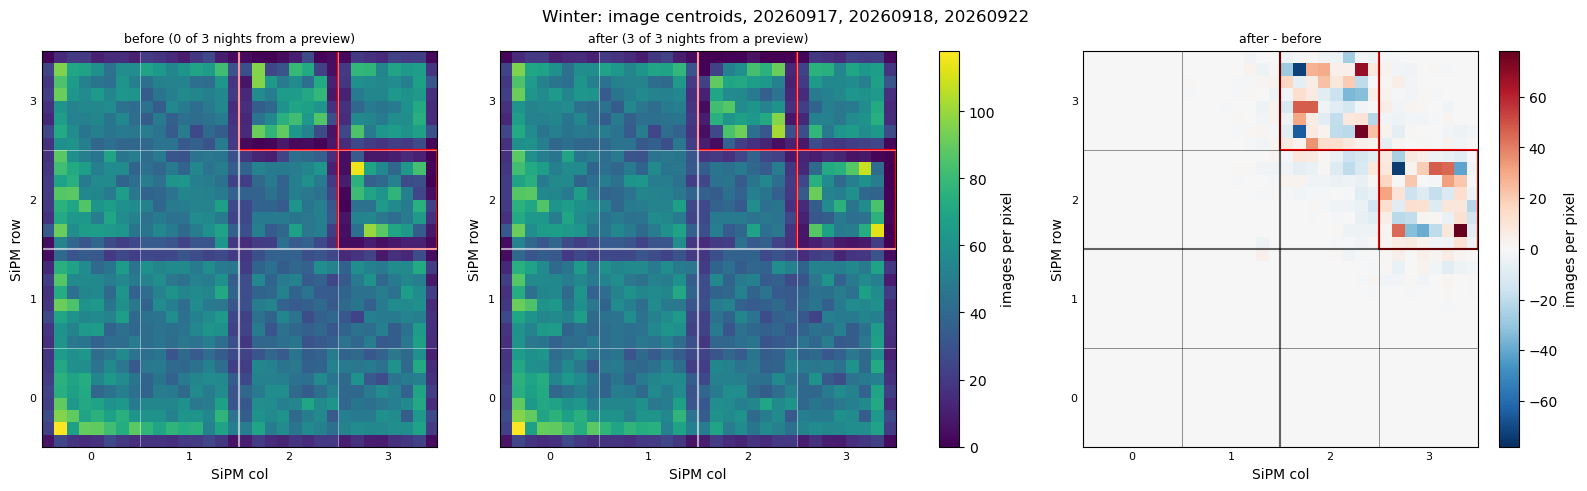

In [8]:
if comparison:
    sipms = sorted({tuple(sipm) for date in FIX_DATES for sipm in rotated_sipm_for(TELESCOPE, date)})
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
    counts = {}
    for ax, (i, label) in zip(axs, [(1, "before"), (3, "after")]):
        n_preview = sum(c[4 if label == "before" else 5] == "preview" for c in comparison.values())
        params = pd.concat([c[i] for c in comparison.values()], ignore_index=True)
        im, counts[label] = plot_centroids(ax, params, f"{label} ({n_preview} of {len(comparison)} nights from a preview)", sipms)
    for ax in axs[:2]:
        ax.images[0].set_clim(0, max(c.max() for c in counts.values()))
    fig.colorbar(im, ax=axs[:2], label="images per pixel")
    difference = counts["after"] - counts["before"]
    limit = np.abs(difference).max()
    im = axs[2].imshow(difference, origin="lower", extent=CAMERA_EXTENT, cmap="RdBu_r", vmin=-limit, vmax=limit)
    draw_grid(axs[2], sipms, color="k")
    axs[2].set_title("after - before", fontsize=9)
    fig.colorbar(im, ax=axs[2], label="images per pixel")
    fig.suptitle(f"{TELESCOPE}: image centroids, {', '.join(FIX_DATES)}")
    plt.show()

## Images in the rotated SiPMs
The `N_IMAGES` images with the most light in the rotated SiPMs, among those with `MIN_PIXELS` or more pixels and at
least `MIN_FRACTION` of their size in the rotated SiPMs' quabos, before (top) and after (bottom), the rotated SiPMs
outlined in red.

9864 images with at least 50% of their size in the rotated SiPMs' quabos; the 6 with the most light in the rotated SiPMs:


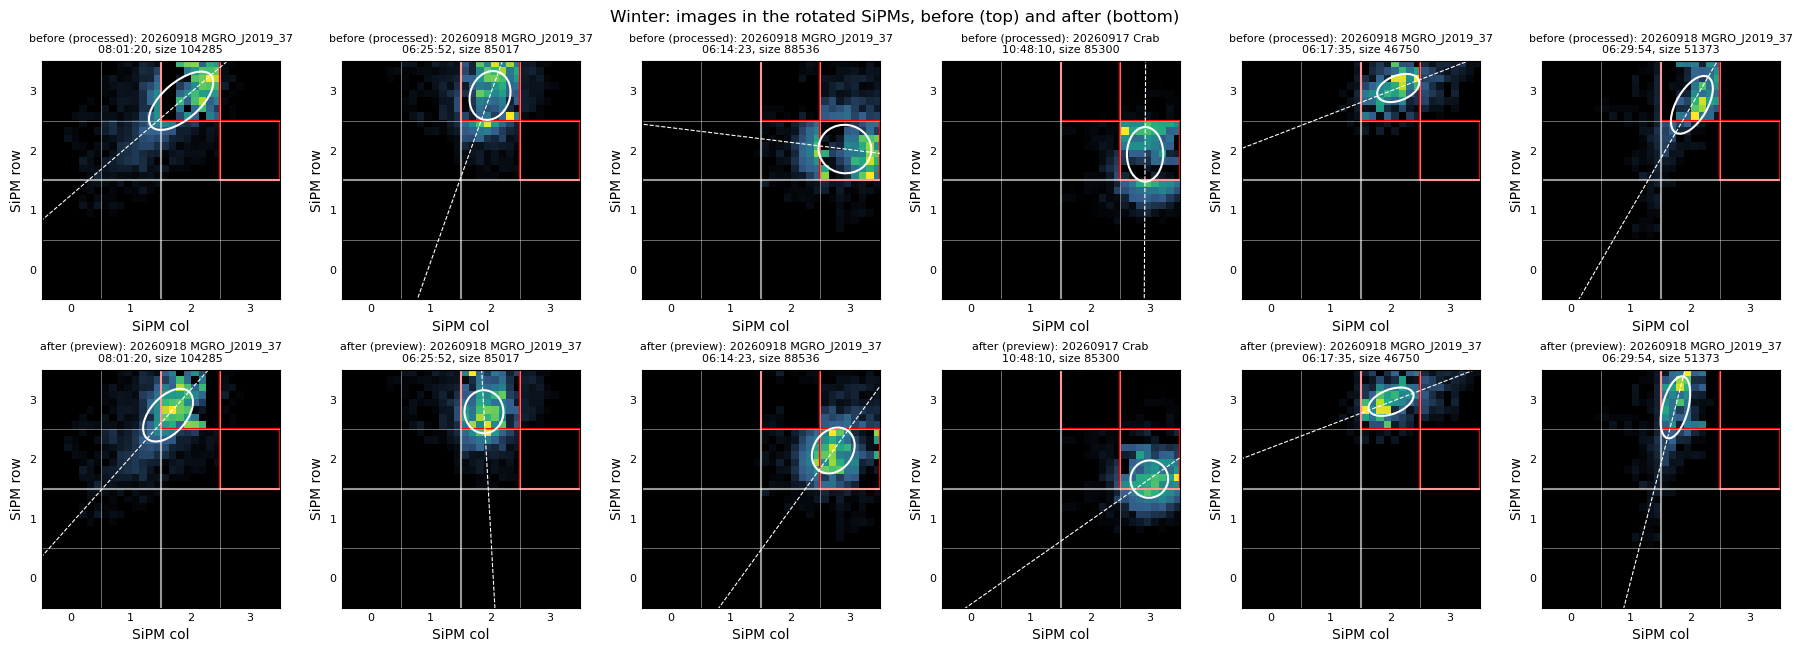

In [9]:
if comparison:
    candidates = [] # (light in the rotated SiPMs, date, index before, index after)
    for date, (images_before, params_before, images_after, params_after, *_) in comparison.items():
        sipms = rotated_sipm_for(TELESCOPE, date)
        after_index = pd.Series(np.arange(len(params_after)), index=pd.MultiIndex.from_frame(params_after[["Source", "Timestamp"]]))
        keep = (params_before.N_pix.to_numpy() >= MIN_PIXELS) & (region_fraction(images_before, quabo_sipms(sipms)) >= MIN_FRACTION)
        light = region_fraction(images_before, sipms) * params_before["size"].to_numpy()
        for i in np.nonzero(keep)[0]:
            key = (params_before.Source.iloc[i], params_before.Timestamp.iloc[i])
            if key in after_index.index:
                candidates.append((light[i], date, i, int(after_index[key])))
    picks = [pick[1:] for pick in sorted(candidates, key=lambda pick: pick[0], reverse=True)[:N_IMAGES]]
    print(f"{len(candidates)} images with at least {MIN_FRACTION:.0%} of their size in the rotated SiPMs' quabos; the {len(picks)} "
          f"with the most light in the rotated SiPMs:")
    fig, axs = plt.subplots(2, len(picks), figsize=(3*len(picks), 6.4), squeeze=False, layout="constrained")
    for col, (date, i, j) in enumerate(picks):
        images_before, params_before, images_after, params_after, before_kind, after_kind = comparison[date]
        sipms = rotated_sipm_for(TELESCOPE, date)
        for row, (image, params, label) in enumerate([(images_before[i], params_before.iloc[i], "before"),
                                                      (images_after[j], params_after.iloc[j], "after")]):
            kind = before_kind if label == "before" else after_kind
            plot_image(axs[row, col], image, params, f"{label} ({kind}): {date} {params.Source}\n"
                       f"{pd.to_datetime(params.Timestamp, unit='s'):%H:%M:%S}, size {params['size']:.0f}", sipms)
    fig.suptitle(f"{TELESCOPE}: images in the rotated SiPMs, before (top) and after (bottom)")
    plt.show()